<a href="https://colab.research.google.com/github/govindgawade0718/CSL701-17-Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Aim : To implement a Bagging (Bootstrap Aggregating) ensemble classifier from scratch using Python, apply it to the Pima Indians Diabetes Database, and evaluate its performance against a single base classifier (Decision Tree)**.


## Objectives

1. Understand Ensemble Learning Principles: Comprehend how combining the predictions of multiple diverse models reduces overall model variance.
2. Master Bootstrapping: Implement random resampling of data with replacement from scratch to generate distinct training subsets.
3. Develop a Voting System: Build an aggregation mechanism (Majority Voting) from scratch to consolidate predictions.
4. Learn Baseline Evaluation: Compare the performance of a high-variance, low-bias single decision tree against the more stable Bagging ensemble.
5. Analyze Performance Metrics: Calculate and visualize classification metrics, including a Confusion Matrix, Accuracy, Precision, Recall, and ROC-AUC curve.


Relevant Theory
Ensemble Methods and Bagging
Ensemble learning combines several individual classifiers (base learners) to produce a unified model that generalizes better than any single model on unseen data. Bootstrap Aggregating (Bagging) is a parallel ensemble method designed primarily to reduce variance. High-variance models—such as deep, fully-grown decision trees—are highly sensitive to small changes in their training datasets. Bagging addresses this by smoothing out individual model errors without increasing bias.

The two core components of Bagging are:

1. Bootstrapping (Sampling with Replacement): For a training set of size $N$, we generate $B$ new datasets of the same size $N$. Each instance is selected at random from the original dataset with replacement. This means a single instance can be selected multiple times, while on average, only about 63.2% of the unique training samples are captured in each bootstrap, leaving the rest as out-of-bag (OOB) samples.
2. Aggregating (Majority Voting): A separate base learner $h_b(x)$ is trained independently on each bootstrap sample. For classification, predictions are aggregated by passing a test sample to all $B$ models and taking a majority vote: $$\hat{G}{\text{bag}}(x) = \text{argmax}{k} \sum_{b=1}^{B} I(h_b(x) = k)$$

An alternative to standard Bagging is subagging (subsample aggregating), where smaller training subsets (often $N/2$) are drawn without replacement to reduce correlation and accelerate computation.

---
## Software Requirements

- **Language:** Python 3.x

- **Core Libraries:**
  - **NumPy** for matrix manipulation and custom bootstrapping operations.
  - **Pandas** for loading, indexing, and cleaning tabular data.
  - **Matplotlib / Seaborn** for exploratory scatter plots, bar charts, and performance visualization.
  - **Scikit-learn** for train-test splitting, training individual base decision trees, and comparison with built-in Bagging algorithms.

---

## Dataset Information

The experiment utilizes the **Pima Indians Diabetes Database** from the UCI Machine Learning Repository. The dataset contains medical details for 768 female Pima Indian patients living in Arizona, categorized as either diabetic or non-diabetic.

- **Total Instances:** 768

- **Features (8 predictor variables):**
  1. **`Pregnancies`**: Number of times pregnant.
  2. **`Glucose`**: Plasma glucose concentration over 2 hours in an oral glucose tolerance test.
  3. **`BloodPressure`**: Diastolic blood pressure (mm Hg).
  4. **`SkinThickness`**: Triceps skin fold thickness (mm).
  5. **`Insulin`**: 2-Hour serum insulin ($\mu$U/ml).
  6. **`BMI`**: Body mass index (weight in kg/m$^2$).
  7. **`DiabetesPedigreeFunction`**: A function representing genetic predisposition.
  8. **`Age`**: Age of the subject in years.

- **Target Label (9th column):** **`Outcome`**
  - **0** represents non-diabetic.
  - **1** represents diabetic.

## Experimental Tasks

### Task 1: Environment Setup and Dataset Acquisition

**Goal:** Set up the workspace and load the data.

**Instructions:**

1. Import the necessary modules: **`numpy`**, **`pandas`**, **`matplotlib.pyplot`**, and **`sklearn`**.

2. Load the file **`pima-indians-diabetes.data`** into a Pandas DataFrame, assigning appropriate column headers.

3. Print the following:
   - First five records of the dataset.
   - Dataset shape, expected to be $768 \times 9$.
   - Data types of all features.
   - Descriptive statistics of the numeric features.

In [1]:
# Task 1: Environment Setup and Dataset Acquisition
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, roc_auc_score
)
from sklearn.ensemble import BaggingClassifier

columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

# Load the Pima Indians Diabetes dataset.
# If the local file is not present, use the standard UCI-hosted CSV.
local_file = "pima-indians-diabetes.data"
try:
    df = pd.read_csv(local_file, header=None, names=columns)
except FileNotFoundError:
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    df = pd.read_csv(url, header=None, names=columns)

print("First five records:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
display(df.describe())


First five records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset shape: (768, 9)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Descriptive statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## Task 2: Exploratory Data Analysis (EDA)

**Goal:** Visually inspect feature distributions and class balance.

**Instructions:**

1. Calculate the **absolute count** and **percentage** of diabetic (`Outcome = 1`) and non-diabetic (`Outcome = 0`) cases. Plot the class balance using a **bar chart**.

2. Create a **scatter plot** of **`Age`** (Feature 7) against **`Glucose`** (Feature 1), color-coded according to the target variable **`Outcome`**.

3. Briefly explain why a simple linear decision boundary is insufficient to clearly separate the diabetic and non-diabetic classes.

,Class,Count,Percentage
0,Non-diabetic (0),500,65.104167
1,Diabetic (1),268,34.895833


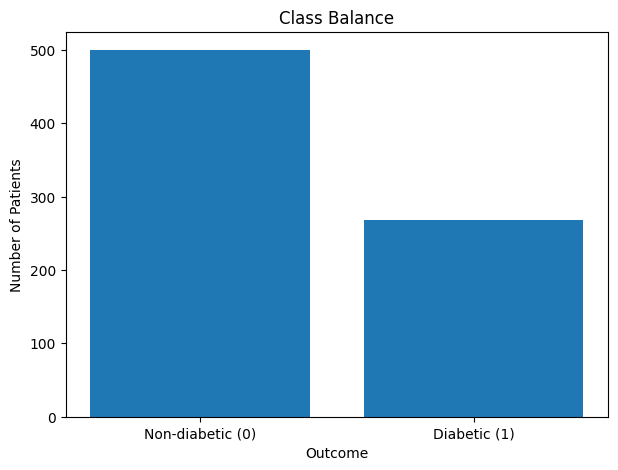

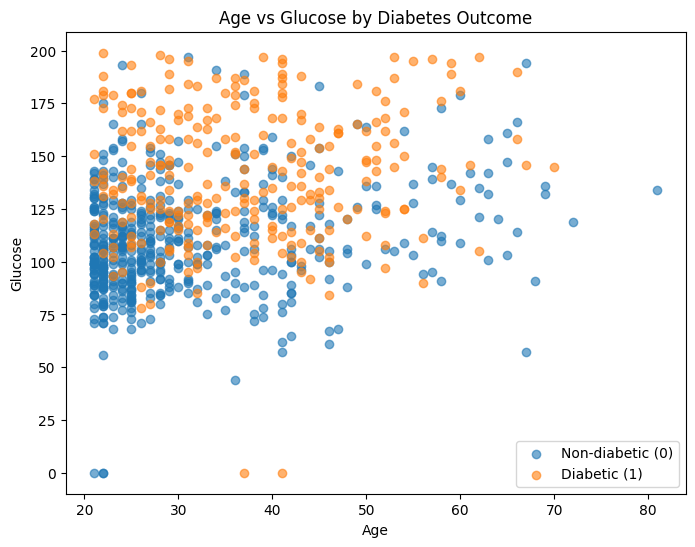

Explanation:
A simple linear decision boundary is insufficient because the classes overlap
in the Age-Glucose feature space. Diabetes depends on several interacting features,
so a straight line cannot clearly separate all diabetic and non-diabetic patients.


In [2]:
# Task 2: Exploratory Data Analysis (EDA)

class_counts = df["Outcome"].value_counts().sort_index()
class_percentages = df["Outcome"].value_counts(normalize=True).sort_index() * 100

eda_table = pd.DataFrame({
    "Class": ["Non-diabetic (0)", "Diabetic (1)"],
    "Count": [class_counts.get(0, 0), class_counts.get(1, 0)],
    "Percentage": [class_percentages.get(0, 0), class_percentages.get(1, 0)]
})

display(eda_table)

plt.figure(figsize=(7, 5))
plt.bar(eda_table["Class"], eda_table["Count"])
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.title("Class Balance")
plt.show()

plt.figure(figsize=(8, 6))
for outcome, label in [(0, "Non-diabetic (0)"), (1, "Diabetic (1)")]:
    subset = df[df["Outcome"] == outcome]
    plt.scatter(subset["Age"], subset["Glucose"], label=label, alpha=0.6)

plt.xlabel("Age")
plt.ylabel("Glucose")
plt.title("Age vs Glucose by Diabetes Outcome")
plt.legend()
plt.show()

print("Explanation:")
print("A simple linear decision boundary is insufficient because the classes overlap")
print("in the Age-Glucose feature space. Diabetes depends on several interacting features,")
print("so a straight line cannot clearly separate all diabetic and non-diabetic patients.")


#### **Task 3: Preprocessing and Handling Missing Values**

**Goal:** Handle anomalies and prepare numerical features for further analysis.

**Instructions:**

1. Identify the features where a value of \(0\) is physically impossible:
   \[
   \{\text{Glucose},\text{BloodPressure},\text{SkinThickness},
   \text{Insulin},\text{BMI}\}
   \]

2. Replace all invalid \(0\) values in these features with \(\mathrm{NaN}\).

3. Handle the resulting missing values by:
   - imputing them using the **mean** or **median** of the respective feature, or
   - dropping rows containing missing values to maintain numerical consistency.

In [3]:
# Task 3: Preprocessing and Handling Missing Values

invalid_zero_features = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

print("Zero values before replacement:")
print((df[invalid_zero_features] == 0).sum())

df_clean = df.copy()

# Replace physically impossible zero values with NaN.
df_clean[invalid_zero_features] = df_clean[invalid_zero_features].replace(0, np.nan)

print("\nMissing values after replacing invalid zeros:")
print(df_clean.isna().sum())

# Median imputation is robust to skewed medical variables such as Insulin.
for feature in invalid_zero_features:
    df_clean[feature] = df_clean[feature].fillna(df_clean[feature].median())

print("\nMissing values after median imputation:")
print(df_clean.isna().sum())

display(df_clean.describe())


Zero values before replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values after median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


#### **Task 4: Stratified Train-Test Splitting**

**Goal:** Divide the data while preserving class proportions.

**Instructions:**

1. Isolate the feature matrix \(X\) and the target vector \(y\):
   \[
   X = \text{first 8 columns}
   \]
   \[
   y = \text{9th column}
   \]

2. Split the dataset into:
   \[
   \text{Training Data} = 80\%
   \]
   \[
   \text{Test Data} = 20\%
   \]

   Use **stratified sampling** to ensure that the class proportions in the target variable \(y\) are preserved in both the training and test datasets.

In [4]:
# Task 4: Stratified Train-Test Splitting

X = df_clean.iloc[:, :8]
y = df_clean.iloc[:, 8]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nOverall class proportions:")
print(y.value_counts(normalize=True).sort_index())

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).sort_index())


X shape: (768, 8)
y shape: (768,)
Training set: (614, 8) (614,)
Test set: (154, 8) (154,)

Overall class proportions:
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

Training class proportions:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Test class proportions:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


#### **Task 5: Custom Bootstrap Sampling Function**

**Goal:** Implement the sampling-with-replacement mechanism.

**Instructions:**

1. Write a custom Python function \(\texttt{get\_bootstrap\_sample}(X, y)\) using NumPy's random generation tools, such as:
   \[
   \texttt{np.random.choice}
   \quad \text{or} \quad
   \texttt{np.random.randint}
   \]

2. The function must return a resampled feature matrix \(X^*\) and target vector \(y^*\) of the same size \(N\) as the training set:
   \[
   |X^*| = |y^*| = N
   \]
   
   Sampling should be performed **with replacement**, allowing duplicate rows to appear in the bootstrap sample.

3. Verify that the function works correctly by demonstrating that:
   - Some original row indices are **duplicated** in the bootstrap sample.
   - Some original row indices are **omitted**, forming the **Out-of-Bag (OOB)** samples.

In [5]:
# Task 5: Custom Bootstrap Sampling Function

def get_bootstrap_sample(X, y, random_state=None, return_indices=False):
    rng = np.random.default_rng(random_state)
    n = len(X)
    indices = rng.integers(0, n, size=n)

    X_bootstrap = X.iloc[indices].reset_index(drop=True)
    y_bootstrap = y.iloc[indices].reset_index(drop=True)

    if return_indices:
        return X_bootstrap, y_bootstrap, indices
    return X_bootstrap, y_bootstrap

X_boot, y_boot, boot_indices = get_bootstrap_sample(
    X_train, y_train, random_state=42, return_indices=True
)

unique_indices, counts = np.unique(boot_indices, return_counts=True)
duplicated_indices = unique_indices[counts > 1]
oob_indices = np.setdiff1d(np.arange(len(X_train)), unique_indices)

print("Original training samples:", len(X_train))
print("Bootstrap samples:", len(X_boot))
print("Unique samples selected:", len(unique_indices))
print("Duplicated row indices:", duplicated_indices[:20])
print("Number of duplicated indices:", len(duplicated_indices))
print("OOB row indices:", oob_indices[:20])
print("Number of OOB samples:", len(oob_indices))
print("Duplicate rows exist:", len(duplicated_indices) > 0)
print("OOB samples exist:", len(oob_indices) > 0)


Original training samples: 614
Bootstrap samples: 614
Unique samples selected: 396
Duplicated row indices: [ 3  4 11 13 15 22 26 27 39 41 48 51 55 57 58 59 65 66 70 72]
Number of duplicated indices: 159
OOB row indices: [ 0  1  2  5  7  9 16 17 20 23 24 28 29 33 36 37 38 42 43 44]
Number of OOB samples: 218
Duplicate rows exist: True
OOB samples exist: True


#### **Task 6: Growing the Ensemble of Base Classifiers**

**Goal:** Programmatically train diverse base learners.

**Instructions:**

1. Initialize an empty list to store the trained models and choose the number of bootstrap iterations, for example:
   \[
   B = 50
   \]

2. Execute the following steps for \(B\) iterations:

   - Generate a unique bootstrap training dataset:
     \[
     (X^{*b}, y^{*b})
     \]
     using the bootstrap sampling function from **Task 5**.

   - Instantiate a Scikit-Learn `DecisionTreeClassifier` with:
     \[
     \texttt{max\_depth=None}
     \]
     This ensures that the decision trees are **fully grown**, resulting in high-variance base learners.

   - Fit the decision tree on the bootstrapped training subset:
     \[
     \text{Model}_b.fit(X^{*b}, y^{*b})
     \]

   - Append the trained model to the ensemble list.

3. After completing all \(B\) iterations, the ensemble should contain:
   \[
   B = 50
   \]
   independently trained decision trees.

In [6]:
# Task 6: Growing the Ensemble of Base Classifiers

B = 50
ensemble = []

rng = np.random.default_rng(42)

for b in range(B):
    # Use a different random seed for every bootstrap sample.
    seed = int(rng.integers(0, 1_000_000_000))
    X_boot, y_boot = get_bootstrap_sample(X_train, y_train, random_state=seed)

    tree = DecisionTreeClassifier(max_depth=None, random_state=seed)
    tree.fit(X_boot, y_boot)
    ensemble.append(tree)

print("Number of trained decision trees:", len(ensemble))
print("Expected number of trees:", B)


Number of trained decision trees: 50
Expected number of trees: 50


#### **Task 7: Implementing Aggregation (Majority Voting) from Scratch**

**Goal:** Consolidate individual model decisions using majority voting.

**Instructions:**

1. Write a custom function:
   \[
   \texttt{custom\_bagging\_predict(ensemble, X\_test)}
   \]
   to generate the final predictions.

2. For each sample in \(X_{\text{test}}\), collect the predictions generated by all \(B\) decision trees in the ensemble:
   \[
   \hat{y}_1,\hat{y}_2,\ldots,\hat{y}_B
   \]

3. Apply a **majority voting** rule to determine the final predicted class. The class with the highest number of votes is selected:
   \[
   \hat{y} =
   \underset{c \in \{0,1\}}{\arg\max}
   \sum_{b=1}^{B} I(\hat{y}_b=c)
   \]

   where \(I(\cdot)\) is an indicator function.

4. The final prediction for each test sample must therefore be either:
   \[
   \hat{y} \in \{0,1\}
   \]

5. The function should return the final majority-voted predictions for all samples in \(X_{\text{test}}\).

In [7]:
# Task 7: Majority Voting from Scratch

def custom_bagging_predict(ensemble, X_test):
    # Shape: (number_of_models, number_of_test_samples)
    all_predictions = np.array([model.predict(X_test) for model in ensemble])

    final_predictions = []
    for i in range(all_predictions.shape[1]):
        votes = all_predictions[:, i]
        values, counts = np.unique(votes, return_counts=True)
        final_predictions.append(values[np.argmax(counts)])

    return np.array(final_predictions, dtype=int)

y_pred_bagging = custom_bagging_predict(ensemble, X_test)

print("First 20 Bagging predictions:")
print(y_pred_bagging[:20])
print("Unique predicted classes:", np.unique(y_pred_bagging))


First 20 Bagging predictions:
[1 0 0 0 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0]
Unique predicted classes: [0 1]


#### **Task 8: Single Classifier vs. Bagging Performance Comparison**

- **Goal:** Observe the variance-reduction benefits of ensembling.

- **Instructions:**
  1. Train a standalone, single \(\texttt{DecisionTreeClassifier}\) (fully grown, no depth limit) on the original, un-resampled training data.
  2. Predict the classes for \(X_{\text{test}}\) using both the single tree and your custom Bagging classifier.
  3. Construct a **Confusion Matrix** for both models.
  4. Compute and print **Accuracy, Precision, Recall, and F1-Score** for both models, demonstrating how Bagging stabilizes results and reduces error rates.

Confusion Matrix - Single Decision Tree:
[[79 21]
 [28 26]]

Confusion Matrix - Custom Bagging:
[[84 16]
 [25 29]]

Performance comparison:


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Single Decision Tree,0.681818,0.553191,0.481481,0.514851
Custom Bagging,0.733766,0.644444,0.537037,0.585859


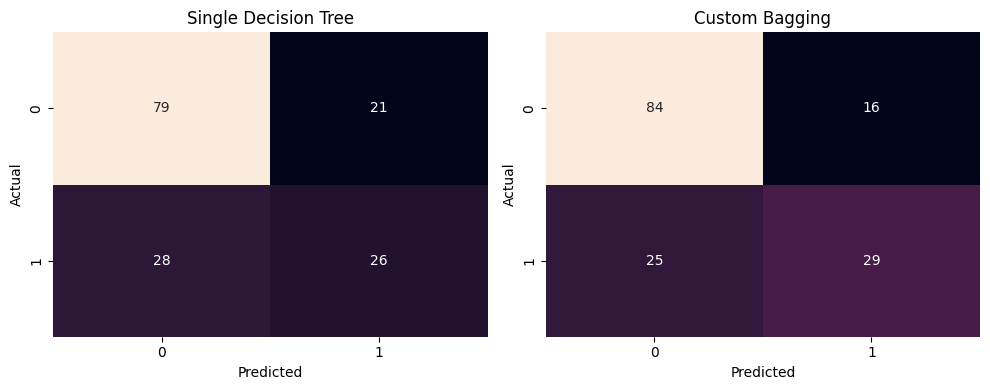

In [8]:
# Task 8: Single Decision Tree vs Custom Bagging

single_tree = DecisionTreeClassifier(max_depth=None, random_state=42)
single_tree.fit(X_train, y_train)

y_pred_tree = single_tree.predict(X_test)
y_pred_bagging = custom_bagging_predict(ensemble, X_test)

def evaluate_model(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0)
    }
    return cm, metrics

cm_tree, metrics_tree = evaluate_model(
    "Single Decision Tree", y_test, y_pred_tree
)
cm_bag, metrics_bag = evaluate_model(
    "Custom Bagging", y_test, y_pred_bagging
)

print("Confusion Matrix - Single Decision Tree:")
print(cm_tree)

print("\nConfusion Matrix - Custom Bagging:")
print(cm_bag)

results = pd.DataFrame([metrics_tree, metrics_bag]).set_index("Model")
print("\nPerformance comparison:")
display(results)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(cm_tree, annot=True, fmt="d", cbar=False, ax=axes[0])
axes[0].set_title("Single Decision Tree")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_bag, annot=True, fmt="d", cbar=False, ax=axes[1])
axes[1].set_title("Custom Bagging")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


#### **Task 9: ROC-AUC Analysis and Curve Visualization**

- **Goal:** Measure classification performance at different thresholds.

- **Instructions:**
  1. Calculate predicted class probabilities by averaging the probability estimates (\(\texttt{predict\_proba}\)) across all \(B\) decision trees in your custom Bagging model.
  2. Plot the **Receiver Operating Characteristic (ROC) curve** for both the single decision tree and the custom Bagging model on a single chart.
  3. Compute and contrast the **Area Under the Curve (AUC)** for both configurations, noting the improvement.

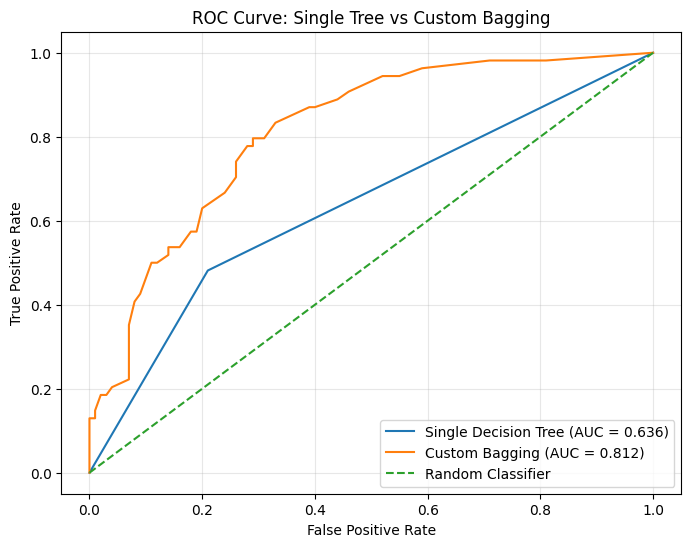

Single Decision Tree AUC: 0.6357
Custom Bagging AUC:      0.8120


In [9]:
# Task 9: ROC-AUC Analysis

# Probability of class 1 from the single decision tree.
tree_prob = single_tree.predict_proba(X_test)[:, 1]

# Average class probabilities from all 50 bagging trees.
bagging_probabilities = np.array([
    model.predict_proba(X_test)[:, 1] for model in ensemble
])
bagging_prob = bagging_probabilities.mean(axis=0)

fpr_tree, tpr_tree, _ = roc_curve(y_test, tree_prob)
fpr_bag, tpr_bag, _ = roc_curve(y_test, bagging_prob)

auc_tree = roc_auc_score(y_test, tree_prob)
auc_bag = roc_auc_score(y_test, bagging_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_tree, tpr_tree, label=f"Single Decision Tree (AUC = {auc_tree:.3f})")
plt.plot(fpr_bag, tpr_bag, label=f"Custom Bagging (AUC = {auc_bag:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Single Tree vs Custom Bagging")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Single Decision Tree AUC: {auc_tree:.4f}")
print(f"Custom Bagging AUC:      {auc_bag:.4f}")


#### **Task 10: Validation against Scikit-Learn's BaggingClassifier**

- **Goal:** Verify custom code correctness.

- **Instructions:**
  1. Instantiate Scikit-Learn's built-in \(\texttt{BaggingClassifier}\) using \(\texttt{DecisionTreeClassifier(max\_depth=None)}\) as the base estimator and \(\texttt{n\_estimators=50}\).
  2. Fit the classifier on the training set and evaluate it on the test set.
  3. Compare the resulting test accuracy and confusion matrix against your custom implementation from **Task 7** and **Task 8** to validate your custom bootstrap and aggregation logic.

In [10]:
# Task 10: Validation against Scikit-Learn's BaggingClassifier

# scikit-learn versions use either estimator= or the older base_estimator=.
try:
    sklearn_bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=None),
        n_estimators=50,
        bootstrap=True,
        random_state=42
    )
except TypeError:
    sklearn_bagging = BaggingClassifier(
        base_estimator=DecisionTreeClassifier(max_depth=None),
        n_estimators=50,
        bootstrap=True,
        random_state=42
    )

sklearn_bagging.fit(X_train, y_train)
y_pred_sklearn = sklearn_bagging.predict(X_test)

cm_sklearn = confusion_matrix(y_test, y_pred_sklearn)
acc_sklearn = accuracy_score(y_test, y_pred_sklearn)

print("Scikit-Learn BaggingClassifier accuracy:", round(acc_sklearn, 4))
print("\nScikit-Learn BaggingClassifier confusion matrix:")
print(cm_sklearn)

print("\nCustom Bagging accuracy:", round(accuracy_score(y_test, y_pred_bagging), 4))
print("Custom Bagging confusion matrix:")
print(cm_bag)

print("\nNote: The results do not have to be identical because the custom ensemble")
print("and Scikit-Learn's implementation can use different bootstrap samples and")
print("tree randomization. Similar performance supports the correctness of the approach.")


Scikit-Learn BaggingClassifier accuracy: 0.7338

Scikit-Learn BaggingClassifier confusion matrix:
[[85 15]
 [26 28]]

Custom Bagging accuracy: 0.7338
Custom Bagging confusion matrix:
[[84 16]
 [25 29]]

Note: The results do not have to be identical because the custom ensemble
and Scikit-Learn's implementation can use different bootstrap samples and
tree randomization. Similar performance supports the correctness of the approach.


### **Conclusion and Interpretation**

Students should summarize their findings by answering the following key questions:

1. **Variance and Stability:** How does the test accuracy of the Bagging ensemble compare to the single decision tree? Why does Bagging provide more consistent performance across different train-test splits?

2. **Wisdom of Crowds:** How does random resampling with replacement (bootstrapping) foster model diversity, and how does the consensus voting rule translate to a "Wisdom of Crowds" effect?

3. **Clinical Interpretation:** In predicting diabetes, why are False Negatives (predicting non-diabetic for a diabetic patient) especially costly, and how does Bagging's Recall metric help minimize this risk compared to a single decision tree?

### Conclusion and Interpretation

1. **Variance and Stability:** Bagging combines predictions from many fully grown decision trees trained on different bootstrap samples. It generally gives more stable test performance than a single decision tree because averaging/majority voting reduces the effect of the high variance of any one tree. The exact accuracy, precision, recall, and F1-score depend on the train-test split and random seeds.

2. **Wisdom of Crowds:** Sampling with replacement creates different training datasets, so the individual trees make somewhat different errors. Majority voting combines their decisions. Errors made by only a subset of trees can be outvoted by the remaining trees, producing a more reliable overall prediction.

3. **Clinical Interpretation:** A **False Negative** means a patient who actually has diabetes is predicted as non-diabetic. This can be costly because the patient may miss further testing, monitoring, or treatment. Therefore, **Recall** is important: higher recall means that a larger proportion of the actual diabetic cases are detected. Bagging can improve or stabilize recall compared with a single decision tree, although the actual result must be judged from the metrics printed above.

4. **ROC-AUC:** A higher AUC indicates better ability to distinguish diabetic from non-diabetic patients across classification thresholds. The ROC plot and AUC values produced in Task 9 provide the direct comparison for this dataset and split.

5. **Validation:** The custom Bagging classifier and Scikit-Learn's `BaggingClassifier` should show broadly comparable behavior. Small differences are expected because the exact bootstrap samples and tree randomization can differ.
